# 04 · Avaliação
Fase 5 do CRISP-DM: os resultados respondem às perguntas do negócio? É a mesma análise da página **Avaliação** do app (`src/jogo.avaliar_juizes`).

> **Dados:** enquanto a turma não joga, os notebooks usam `data/processed/capturas_demo.csv` (fictício, gerado por `python -m src.exemplo`). Para usar os dados reais, baixe o CSV na página **Avaliação** do app e salve como `data/processed/avaliacao_juizes.csv`: os notebooks passam a ler esse arquivo sozinhos. As conclusões abaixo só valem de verdade com os dados reais.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.clustering import agrupar, escolher_k
from src.jogo import NOMES_ESTILO, avaliar_juizes

sns.set_theme(style="whitegrid")
capturas = pd.read_csv(RAIZ / "data/processed/capturas_limpas.csv", parse_dates=["criado_em"])
perfis = pd.read_csv(RAIZ / "data/processed/perfis_jogadores.csv", index_col="usuario")
capturas["aceita"] = capturas["aceita"].astype(bool)
a = avaliar_juizes(capturas)
print("Fotos julgadas pelos dois:", a["comparadas"])

Fotos julgadas pelos dois: 198


## Pergunta 1 · Os juízes acertam?

Concordância CLIP × IA: 81% (meta: > 80%)
Achados com modelo/espécie/raça entre as aceitas: 100%


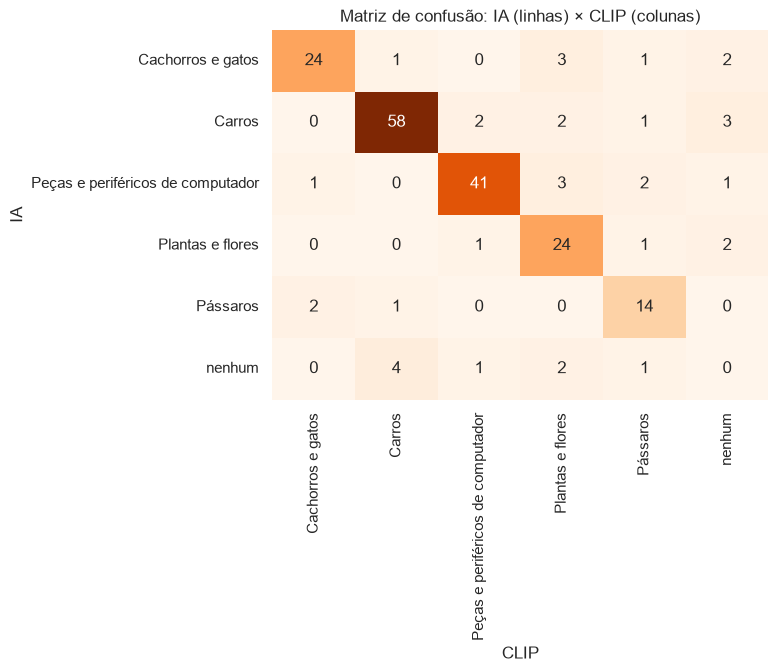

In [2]:
print(f"Concordância CLIP × IA: {a['concordancia']:.0%} (meta: > 80%)")
if a["especificos"] is not None:
    print(f"Achados com modelo/espécie/raça entre as aceitas: {a['especificos']:.0%}")
sns.heatmap(a["matriz"], annot=True, fmt="d", cmap="Oranges", cbar=False)
plt.title("Matriz de confusão: IA (linhas) × CLIP (colunas)");

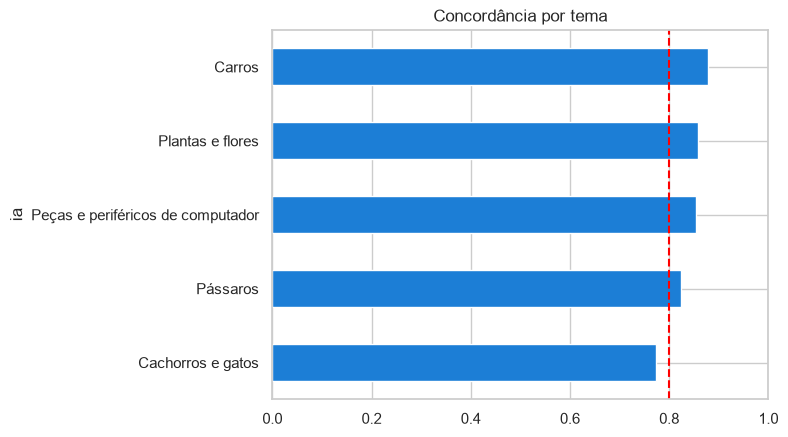

In [3]:
a["por_tema"].plot.barh(color="#1c7ed6", xlim=(0, 1))
plt.axvline(0.8, color="red", ls="--")
plt.title("Concordância por tema");

## Pergunta 2 · O jogo barra a trapaça sem barrar quem joga certo?

In [4]:
print("Recusas por motivo:")
print(a["recusas"].rename(lambda m: m.split(" (")[0]).groupby(level=0).sum().sort_values(ascending=False))
recusadas = int((~capturas["aceita"]).sum())
contestadas = int(a["contestadas"]["vezes"].sum()) if not a["contestadas"].empty else 0
print(f"\nContestadas: {contestadas} de {recusadas} recusas ({contestadas/max(recusadas,1):.0%}; meta: < 10%)")
a["contestadas"]

Recusas por motivo:
motivo
os juízes discordaram do tema    23
não é foto real                   9
não é de nenhum tema do jogo      8
você já achou isso hoje           5
Name: count, dtype: int64

Contestadas: 8 de 45 recusas (18%; meta: < 10%)


,tema_dito,contestada,vezes
0,nenhum,Carros,4
2,nenhum,Plantas e flores,2
1,nenhum,Peças e periféricos de computador,1
3,nenhum,Pássaros,1


## Pergunta 3 · Os estilos de jogador fazem sentido?

In [5]:
tabela = escolher_k(perfis)
rotulos, centros = agrupar(perfis, nomes=NOMES_ESTILO)
silhueta = tabela.set_index("k").loc[len(centros), "silhueta"] if len(centros) in set(tabela["k"]) else float("nan")
print(f"k = {len(centros)}, silhueta = {silhueta:.2f} (meta: > 0,25)")
rotulos["perfil"].value_counts()

k = 4, silhueta = 0.82 (meta: > 0,25)


perfil
Caçador de carros                   3
Naturalista + Observador de aves    2
Amigo dos bichos                    2
Garimpeiro tech                     2
Name: count, dtype: int64

## Pergunta 4 · O tema do dia muda o comportamento?

In [6]:
aceitas = capturas[capturas["aceita"]]
print(f"Fotos aceitas no tema do dia: {aceitas['do_dia'].astype(bool).mean():.0%} "
      f"(sem efeito seria ~{1/5:.0%}, um em cada cinco temas)")

Fotos aceitas no tema do dia: 24% (sem efeito seria ~20%, um em cada cinco temas)


## Conclusão e limitações
Preencha com os números acima quando rodar com `avaliacao_juizes.csv` (dados reais). Com os dados fictícios, os números só mostram que a análise funciona: o gerador foi feito para o CLIP concordar ~85% das vezes e para existirem 4 estilos.

**O que avaliar com os dados reais**
- Se a concordância ficar abaixo de 80% num tema, olhar a matriz de confusão: é a IA ou o CLIP que erra? As contestações desse tema dizem quem tinha razão.
- Se o CLIP vetar muitas fotos por "tela" que as pessoas contestam, subir `RAZAO_TELA` em `src/jogo.py`.
- Se a silhueta ficar abaixo de 0,25, os estilos não são grupos claros: mostrar só o tema preferido.

**Limitações:** não há rótulo verdadeiro independente dos juízes; amostra de uma turma e uma cidade; o CLIP roda num modelo pequeno (ViT-B/32) para caber no Streamlit Cloud gratuito.

**Privacidade (LGPD):** a foto não é guardada (só o hash); a IA recebe a foto sem EXIF/GPS; o CSV não tem nome, bairro, célula nem hash.